# Bagian E3: Naïve Bayes untuk Prediksi Diabetes

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmad-fathan/Fundamentals-of-Data-Science/blob/main/Classification/bab-e3-naive-bayes-prediksi-diabetes.ipynb)

Bagian ini menerapkan **Gaussian Naïve Bayes** pada data kesehatan. Tugasnya adalah memperkirakan apakah seorang pasien mengidap diabetes berdasarkan hasil pemeriksaan sederhana. Kita akan:

1. memuat dan mengenal dataset Diabetes Prediction,
2. melihat sebaran setiap fitur pada kedua kelas,
3. membagi data latih dan data uji,
4. melatih model dan melihat apa yang dipelajari model,
5. memprediksi seorang pasien baru, lalu mencocokkan hasilnya dengan perhitungan manual,
6. mengevaluasi model dan membahas mengapa akurasi saja menyesatkan pada data tidak seimbang.

Bagian E1 membahas Naïve Bayes untuk data tabular pada dataset Penguin, sedangkan Bagian E2 membahas data teks. Bagian ini memakai data tabular yang lebih besar dan tidak seimbang, sehingga cara menilainya berbeda.

Jalankan cell secara berurutan dari atas ke bawah.

## E3.1 Mengimpor Library

In [1]:
%matplotlib inline
import numpy as np                      # komputasi numerik
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi
from scipy.stats import norm            # distribusi normal, untuk perhitungan manual

from sklearn.model_selection import train_test_split            # membagi data latih dan uji
from sklearn.naive_bayes import GaussianNB                      # Naive Bayes untuk fitur angka
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

print("Library berhasil diimpor")

Library berhasil diimpor


## E3.2 Mengenal Dataset Diabetes

Dataset ini berisi 100.000 catatan pasien. Setiap baris memuat beberapa hasil pemeriksaan dan satu label:

- `diabetes = 1` berarti pasien mengidap diabetes,
- `diabetes = 0` berarti tidak.

Fitur yang kita pakai semuanya berupa angka:

- `age` = usia (tahun)
- `hypertension` = riwayat hipertensi (1 = ya, 0 = tidak)
- `heart_disease` = riwayat penyakit jantung (1 = ya, 0 = tidak)
- `bmi` = indeks massa tubuh
- `HbA1c_level` = rata-rata kadar gula darah 2–3 bulan terakhir (persen)
- `blood_glucose_level` = kadar gula darah saat pemeriksaan (mg/dL)

Dataset berasal dari Kaggle, *Diabetes Prediction Dataset* (iammustafatz). Salinannya disimpan di repositori ini agar dapat diunduh langsung tanpa akun Kaggle.

Dua kolom lain, yaitu `gender` dan `smoking_history`, berupa kategori. Keduanya tidak dipakai di sini karena `GaussianNB` hanya menerima fitur angka.

In [2]:
url = ("https://raw.githubusercontent.com/ahmad-fathan/Fundamentals-of-Data-Science/"
       "fdbd0e9/Classification/diabetes_prediction_dataset.csv.gz")
diabetes = pd.read_csv(url)

print("Ukuran data:", diabetes.shape)
diabetes.head()

Ukuran data: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
print("Tipe data setiap kolom:")
print(diabetes.dtypes)
print()
print("Jumlah nilai kosong:", diabetes.isna().sum().sum())

Tipe data setiap kolom:
gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

Jumlah nilai kosong: 0


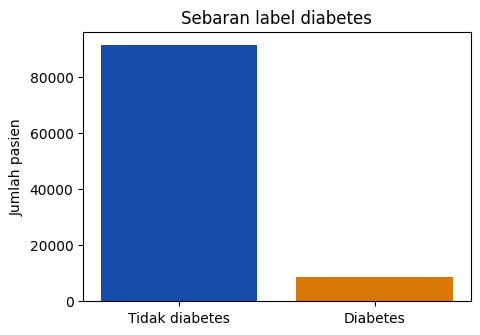

diabetes
0    91500
1     8500
Name: count, dtype: int64
Proporsi diabetes: 0.085


In [4]:
jumlah = diabetes["diabetes"].value_counts().sort_index()

plt.figure(figsize=(5, 3.5))
plt.bar(["Tidak diabetes", "Diabetes"], jumlah.values, color=["#174CAA", "#D97706"])
plt.ylabel("Jumlah pasien")
plt.title("Sebaran label diabetes")
plt.show()

print(jumlah)
print("Proporsi diabetes:", round(diabetes["diabetes"].mean(), 4))

Hanya sekitar **8,5 persen** pasien yang mengidap diabetes. Data seperti ini disebut **tidak seimbang** (*imbalanced*). Akibatnya, akurasi saja tidak cukup untuk menilai model. Model yang selalu menjawab "tidak diabetes" sudah benar sekitar 91,5 persen, padahal tidak pernah menemukan satu pasien diabetes pun. Karena itu, di E3.7 kita juga melihat *recall* untuk kelas diabetes.

Perhatikan juga nilai minimum `age`, yaitu 0,08 tahun. Data ini memuat beberapa catatan bayi, yang sebenarnya tidak lazim pada pemeriksaan diabetes. Kita biarkan apa adanya agar contoh tetap sederhana, tetapi pada data nyata baris seperti ini perlu diperiksa.

## E3.3 Melihat Sebaran Setiap Fitur

Gaussian Naïve Bayes mengasumsikan bahwa, di dalam setiap kelas, nilai sebuah fitur mengikuti distribusi normal. Histogram berikut membandingkan sebaran kedua kelas untuk setiap fitur. Perhatikan bahwa sumbu tegak sengaja tidak disamakan, karena jumlah pasien diabetes jauh lebih sedikit.

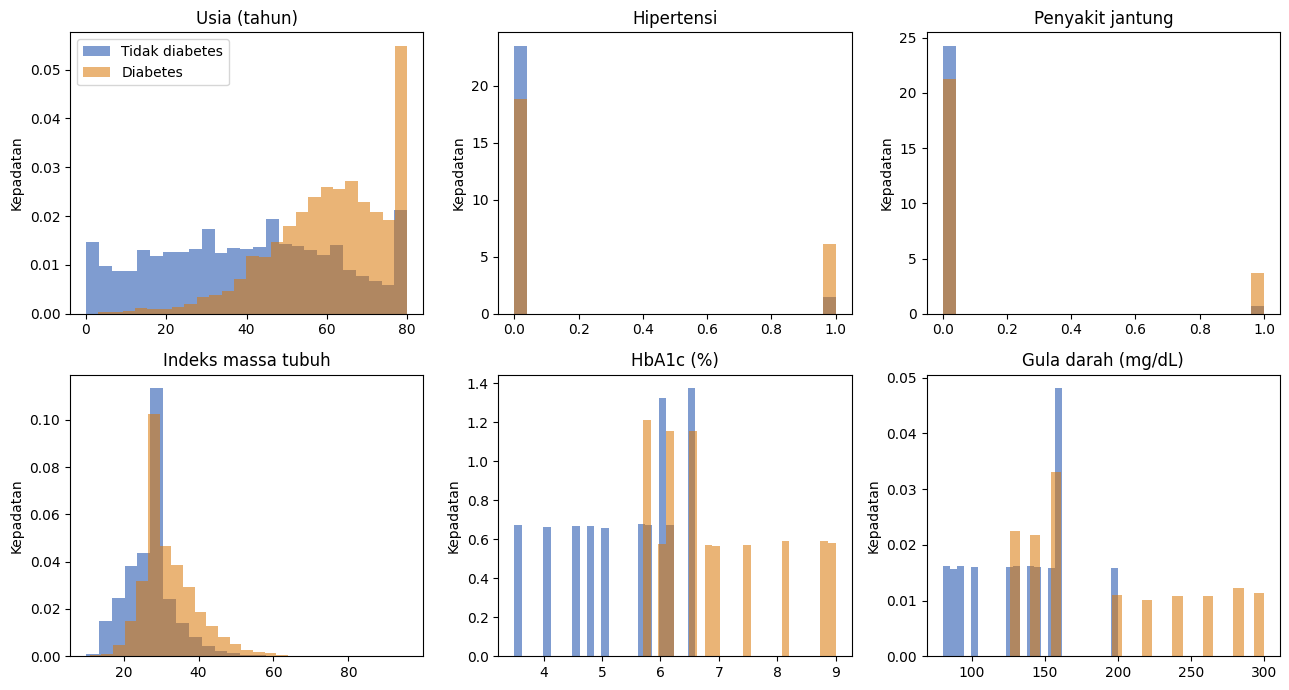

In [5]:
fitur = ["age", "hypertension", "heart_disease", "bmi", "HbA1c_level", "blood_glucose_level"]
nama_fitur = {"age": "Usia (tahun)", "hypertension": "Hipertensi", "heart_disease": "Penyakit jantung",
              "bmi": "Indeks massa tubuh", "HbA1c_level": "HbA1c (%)",
              "blood_glucose_level": "Gula darah (mg/dL)"}
warna = {0: "#174CAA", 1: "#D97706"}
label = {0: "Tidak diabetes", 1: "Diabetes"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), fitur):
    for k in (0, 1):
        nilai = diabetes.loc[diabetes["diabetes"] == k, f]
        ax.hist(nilai, bins=25, alpha=0.55, color=warna[k], label=label[k], density=True)
    ax.set_title(nama_fitur[f])
    ax.set_ylabel("Kepadatan")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

Ada dua hal yang dapat dibaca dari grafik ini:

- **HbA1c dan gula darah memisahkan kedua kelas dengan paling jelas.** Puncak kurva pasien diabetes bergeser jauh ke kanan.
- **Fitur lain kurang tegas.** Usia dan BMI memang bergeser, tetapi kedua kelas masih saling bertumpuk. `hypertension` dan `heart_disease` hanya bernilai 0 atau 1, sehingga bentuknya bukan kurva lonceng sama sekali.

Meskipun asumsi normal tidak sepenuhnya terpenuhi untuk fitur biner, `GaussianNB` tetap dapat dipakai dan hasilnya cukup baik. Di bagian akhir kita bahas keterbatasan ini.

## E3.4 Membagi Data Latih dan Data Uji

Data dibagi menjadi 80 persen data latih dan 20 persen data uji, sehingga tersisa 20.000 pasien untuk pengujian. Parameter `stratify=y` menjaga agar proporsi pasien diabetes tetap sekitar 8,5 persen di kedua bagian, sedangkan `random_state=42` membuat hasil pembagian dapat diulang.

In [6]:
X = diabetes[fitur]         # fitur: DataFrame 2 dimensi
y = diabetes["diabetes"]    # target: 0 atau 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Data latih:", X_train.shape, "| data uji:", X_test.shape)
print("Proporsi diabetes di data latih:", round(y_train.mean(), 4))
print("Proporsi diabetes di data uji  :", round(y_test.mean(), 4))

Data latih: (80000, 6) | data uji: (20000, 6)
Proporsi diabetes di data latih: 0.085
Proporsi diabetes di data uji  : 0.085


## E3.5 Melatih Model Gaussian Naïve Bayes

Untuk fitur angka, likelihood dihitung dari kurva normal setiap kelas:

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i-\mu_y)^2}{2\sigma_y^2}\right) \tag{1}$$

**Keterangan:**

- $P(x_i \mid y)$ = likelihood nilai fitur $x_i$ pada kelas $y$
- $x_i$ = nilai fitur ke-$i$, misalnya kadar HbA1c
- $\mu_y$ = rata-rata fitur tersebut pada kelas $y$
- $\sigma_y$ = standar deviasi fitur tersebut pada kelas $y$
- $\pi$ = konstanta pi, kira-kira 3,14159
- $\exp$ = fungsi eksponensial

Training hanya menghitung **rata-rata** dan **standar deviasi** setiap fitur untuk setiap kelas, ditambah **prior** setiap kelas. Tidak ada proses optimasi berulang seperti pada regresi di Bagian D.

In [7]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Kelas:", model.classes_)

Kelas: [0 1]


Kita lihat apa saja yang dipelajari model. Mulai dari prior, yaitu proporsi setiap kelas pada data latih.

In [8]:
prior = pd.Series(model.class_prior_, index=model.classes_, name="prior")
prior.round(4)

0    0.915
1    0.085
Name: prior, dtype: float64

Berikutnya rata-rata ($\mu$) dan standar deviasi ($\sigma$) setiap fitur untuk setiap kelas. Atribut `theta_` menyimpan rata-rata, sedangkan `var_` menyimpan varians, sehingga standar deviasinya adalah akar dari `var_`.

In [9]:
rata_rata = pd.DataFrame(model.theta_, index=model.classes_, columns=fitur)
std_dev = pd.DataFrame(np.sqrt(model.var_), index=model.classes_, columns=fitur)

print("Rata-rata (mu):")
print(rata_rata.round(2))
print()
print("Standar deviasi (sigma):")
print(std_dev.round(2))

Rata-rata (mu):
     age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level
0  40.14          0.06           0.03  26.89         5.40               132.90
1  60.83          0.25           0.15  31.96         6.94               193.81

Standar deviasi (sigma):
     age  hypertension  heart_disease   bmi  HbA1c_level  blood_glucose_level
0  22.33          0.24           0.17  6.38         0.97                34.25
1  14.53          0.43           0.36  7.54         1.08                58.57


Tabel ini sesuai dengan histogram tadi. Rata-rata HbA1c pasien diabetes sekitar 6,9 persen, sedangkan pasien tanpa diabetes sekitar 5,4 persen. Rata-rata gula darahnya 194 berbanding 133 mg/dL. Usia dan BMI juga lebih tinggi, tetapi selisihnya tidak sebesar kedua fitur tadi. Hanya angka-angka inilah yang disimpan model.

## E3.6 Memprediksi Seorang Pasien Baru

Misalkan seorang pasien berusia 55 tahun datang dengan hasil pemeriksaan berikut. Nilainya sengaja dipilih di antara kedua kelas, supaya keputusannya tidak terlalu mudah.

In [10]:
pasien = pd.DataFrame([{
    "age": 55.0,
    "hypertension": 0,
    "heart_disease": 0,
    "bmi": 28.0,
    "HbA1c_level": 7.2,
    "blood_glucose_level": 170,
}])

proba = model.predict_proba(pasien)[0]
print("Probabilitas [tidak diabetes, diabetes]:", proba.round(4))
print("Prediksi:", model.predict(pasien)[0])

Probabilitas [tidak diabetes, diabetes]: [0.8897 0.1103]
Prediksi: 0


Grafik berikut memperlihatkan cara kerja Persamaan 1 untuk satu fitur, yaitu HbA1c. Kurva digambar dari rata-rata dan standar deviasi yang dipelajari model. Garis putus-putus adalah nilai HbA1c pasien baru, dan titik pada setiap kurva adalah likelihood-nya.

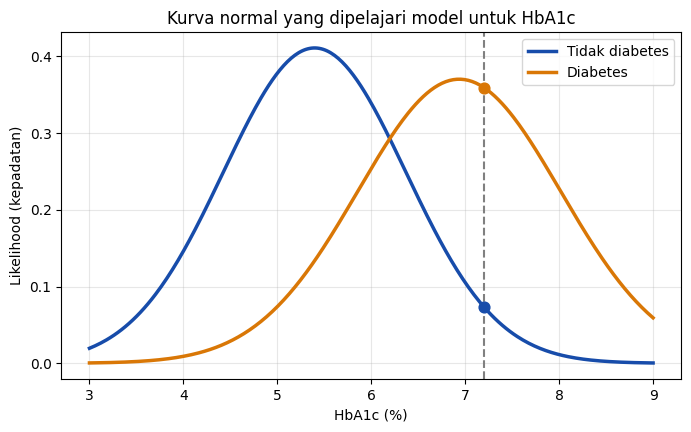

In [11]:
f = "HbA1c_level"
x_baru = pasien[f].iloc[0]
sumbu_x = np.linspace(3, 9, 300)

plt.figure(figsize=(8, 4.5))
for k in (0, 1):
    mu, sigma = rata_rata.loc[k, f], std_dev.loc[k, f]
    plt.plot(sumbu_x, norm.pdf(sumbu_x, mu, sigma), color=warna[k], linewidth=2.5, label=label[k])
    plt.scatter([x_baru], [norm.pdf(x_baru, mu, sigma)], color=warna[k], s=60, zorder=3)
plt.axvline(x_baru, color="gray", linestyle="--")
plt.xlabel("HbA1c (%)")
plt.ylabel("Likelihood (kepadatan)")
plt.title("Kurva normal yang dipelajari model untuk HbA1c")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Pada HbA1c 7,2 persen, kurva pasien diabetes lebih tinggi daripada kurva pasien tanpa diabetes, tetapi tidak terlalu jauh, karena nilai ini masih berada di ekor kanan kurva kelas sehat. Fitur lain, yaitu usia, BMI, dan gula darah, juga hanya sedikit di atas rata-rata kelas sehat. Karena itu buktinya belum cukup kuat untuk mengalahkan prior, dan model menjawab "tidak diabetes" dengan keyakinan sekitar 89 persen.

### Mencocokkan dengan perhitungan manual

Model memakai aturan keputusan yang sama seperti modul:

$$\hat{y} = \arg\max_{y} \; P(y) \prod_{i=1}^{n} P(x_i \mid y) \tag{2}$$

**Keterangan:**

- $\hat{y}$ = kelas hasil prediksi
- $\arg\max_{y}$ = kelas $y$ yang menghasilkan nilai terbesar
- $P(y)$ = prior kelas $y$
- $P(x_i \mid y)$ = likelihood fitur ke-$i$ pada kelas $y$, dihitung dengan Persamaan 1
- $\prod_{i=1}^{n}$ = perkalian untuk keenam fitur
- $n$ = banyaknya fitur, yaitu 6

Kita hitung sendiri likelihood setiap fitur, kalikan dengan prior, lalu normalisasi. Hasilnya harus sama dengan `predict_proba`.

In [12]:
# likelihood setiap fitur untuk setiap kelas (Persamaan 1)
likelihood = pd.DataFrame(
    {f: [norm.pdf(pasien[f].iloc[0], rata_rata.loc[k, f], std_dev.loc[k, f])
         for k in model.classes_] for f in fitur},
    index=model.classes_)

print("Likelihood setiap fitur:")
print(likelihood.map(lambda v: f"{v:.2e}"))

Likelihood setiap fitur:
        age hypertension heart_disease       bmi HbA1c_level  \
0  1.43e-02     1.64e+00      2.33e+00  6.16e-02    7.33e-02   
1  2.53e-02     7.87e-01      1.03e+00  4.61e-02    3.59e-01   

  blood_glucose_level  
0            6.48e-03  
1            6.27e-03  


In [13]:
# skor = prior x hasil kali keenam likelihood (Persamaan 2)
skor = prior * likelihood.prod(axis=1)

# normalisasi: bagi dengan jumlah semua skor
manual = skor / skor.sum()

perbandingan = pd.DataFrame({"skor": skor.map(lambda v: f"{v:.3e}"),
                              "manual": manual.round(4),
                              "predict_proba": proba.round(4)})
perbandingan

,skor,manual,predict_proba
0,1.462e-06,0.8897,0.8897
1,1.813e-07,0.1103,0.1103


**Hasil yang diharapkan:** kolom `manual` dan `predict_proba` bernilai sama. Jadi, `GaussianNB` hanya menjalankan Persamaan 1 dan Persamaan 2 untuk kita.

Perhatikan bahwa kelas diabetes tetap unggul pada beberapa fitur, terutama HbA1c dan gula darah. Meskipun begitu, model memilih "tidak diabetes", karena **prior** kelas itu jauh lebih besar (0,915 berbanding 0,085). Contoh ini memperlihatkan peran prior dalam Teorema Bayes: keyakinan awal ikut menentukan keputusan ketika bukti dari fitur belum cukup kuat.

Skor sebelum normalisasi sangat kecil karena merupakan hasil kali enam likelihood. Pada data dengan banyak fitur, angka ini bisa terlalu kecil untuk disimpan komputer. Karena itu scikit-learn sebenarnya menjumlahkan **logaritma** likelihood, bukan mengalikannya. Hasil akhirnya tetap sama karena logaritma tidak mengubah urutan nilai.

In [14]:
# bandingkan dengan pasien yang hasil pemeriksaannya normal
pasien_sehat = pd.DataFrame([{
    "age": 30.0, "hypertension": 0, "heart_disease": 0,
    "bmi": 22.0, "HbA1c_level": 5.2, "blood_glucose_level": 95,
}])

print("Probabilitas [tidak diabetes, diabetes]:", model.predict_proba(pasien_sehat)[0].round(4))
print("Prediksi:", model.predict(pasien_sehat)[0])

Probabilitas [tidak diabetes, diabetes]: [9.999e-01 1.000e-04]
Prediksi: 0


Kebalikannya terjadi: seluruh fitur berada jauh di bawah rata-rata pasien diabetes, sehingga model hampir pasti menjawab tidak diabetes.

## E3.7 Mengevaluasi Model

Sekarang kita ukur kinerja model pada data uji, yaitu 20.000 pasien yang tidak dilihat model saat training.

In [15]:
y_pred = model.predict(X_test)

print(f"Akurasi data uji: {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, digits=3,
                            target_names=["tidak diabetes", "diabetes"]))

Akurasi data uji: 0.905

                precision    recall  f1-score   support

tidak diabetes      0.967     0.928     0.947     18300
      diabetes      0.458     0.656     0.540      1700

      accuracy                          0.905     20000
     macro avg      0.712     0.792     0.743     20000
  weighted avg      0.923     0.905     0.912     20000



Akurasi sekitar **0,905** terlihat tinggi, tetapi perhatikan pembandingnya: model yang selalu menjawab "tidak diabetes" sudah mendapat **0,915**. Artinya, model Naïve Bayes ini secara akurasi justru **sedikit lebih rendah** daripada menebak semua pasien sebagai sehat.

Namun, akurasi tidak menceritakan seluruhnya. Lihat kelas diabetes: *recall* sekitar 0,66 berarti model berhasil menemukan sekitar dua pertiga pasien diabetes, sesuatu yang tidak dilakukan model pembanding. Nilai *precision* sekitar 0,46 berarti dari pasien yang dinyatakan diabetes, kurang dari separuhnya benar-benar mengidap diabetes. Untuk skrining awal, *recall* yang tinggi biasanya lebih penting daripada *precision*, karena pasien yang terlewat lebih berisiko daripada pasien yang perlu diperiksa ulang.

Kita lihat letak kesalahannya dengan *confusion matrix*. Baris menunjukkan label sebenarnya dan kolom menunjukkan hasil prediksi.

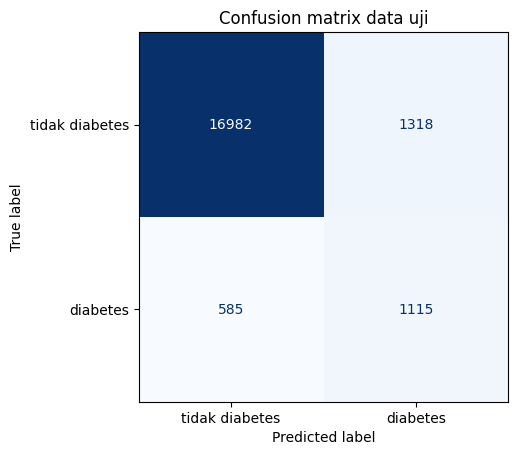

                prediksi: tidak  prediksi: diabetes
asli: tidak               16982                1318
asli: diabetes              585                1115


In [16]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(cm, display_labels=["tidak diabetes", "diabetes"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix data uji")
plt.show()

print(pd.DataFrame(cm, index=["asli: tidak", "asli: diabetes"],
                   columns=["prediksi: tidak", "prediksi: diabetes"]))

Angka di diagonal adalah prediksi yang benar. Kesalahannya ada dua jenis:

- **1.318 pasien sehat** ditebak mengidap diabetes (salah alarm). Jumlahnya lebih dari dua kali lipat jumlah pasien diabetes yang berhasil ditemukan.
- **585 pasien diabetes** justru ditebak sehat (*false negative*). Inilah kesalahan yang paling berbahaya dalam konteks kesehatan.

Perilaku ini muncul karena prior kelas diabetes hanya 0,085. Ketika bukti dari fitur tidak cukup kuat, prior yang kecil membuat model condong menjawab "tidak diabetes". Naïve Bayes selalu mengalikan prior, sehingga hasilnya mengikuti sebaran kelas pada data latih.

### Menggeser ambang keputusan

Secara bawaan, model memilih kelas dengan probabilitas terbesar, yaitu dengan ambang 0,5. Ambang ini dapat diturunkan agar lebih banyak pasien dinyatakan berisiko. Kita bandingkan beberapa nilai ambang.

In [17]:
proba_diabetes = model.predict_proba(X_test)[:, 1]   # peluang kelas 1

baris = []
for ambang in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (proba_diabetes >= ambang).astype(int)
    recall = ((pred == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
    precision = ((pred == 1) & (y_test == 1)).sum() / max((pred == 1).sum(), 1)
    baris.append({"ambang": ambang, "akurasi": accuracy_score(y_test, pred),
                  "precision": precision, "recall": recall})

pd.DataFrame(baris).round(3)

,ambang,akurasi,precision,recall
0,0.5,0.905,0.458,0.656
1,0.4,0.903,0.452,0.678
2,0.3,0.901,0.446,0.698
3,0.2,0.898,0.439,0.724
4,0.1,0.891,0.421,0.764


**Hasil yang diharapkan:** menurunkan ambang menaikkan *recall* tetapi menurunkan *precision* dan akurasi. Tidak ada ambang yang terbaik untuk semua keperluan; pilihannya bergantung pada biaya masing-masing jenis kesalahan. Pada skrining penyakit, ambang rendah lebih masuk akal karena kesalahan melewatkan pasien lebih mahal daripada kesalahan memeriksa ulang pasien sehat.

## E3.8 Latihan

Kerjakan latihan berikut di cell kosong yang tersedia. Gunakan hanya teknik yang sudah dibahas di notebook ini.

**Latihan 1.** Latih `GaussianNB` yang hanya memakai **satu** fitur, yaitu `HbA1c_level`, dengan pembagian data yang sama. Hitung akurasi, *precision*, dan *recall* pada data uji, lalu bandingkan dengan model enam fitur.

*Hasil yang diharapkan:* akurasi sekitar 0,93 tetapi *recall* hanya sekitar 0,23, jauh lebih rendah daripada model enam fitur (0,66). Jelaskan mengapa akurasi bisa lebih tinggi sementara *recall* justru jauh lebih buruk.

In [18]:
# Latihan 1

**Latihan 2.** Ulangi Latihan 1 untuk setiap fitur satu per satu. Fitur mana yang paling berguna jika dipakai sendirian? Apakah jawaban Anda sesuai dengan histogram di E3.3?

*Hasil yang diharapkan:* sebuah tabel kecil berisi nama fitur, akurasi, dan *recall*. Fitur `blood_glucose_level` dan `HbA1c_level` adalah yang paling berguna, sesuai histogram di E3.3. Menarik: `age` sendirian tidak pernah memprediksi diabetes, sedangkan `blood_glucose_level` sendirian justru mencapai akurasi lebih tinggi daripada model enam fitur. Diskusikan kemungkinan penyebabnya.

In [19]:
# Latihan 2

**Latihan 3.** Tambahkan kolom `smoking_history` ke dalam model. Karena kolom ini berupa kategori, ubah dulu menjadi kode angka dengan `OrdinalEncoder`, lalu latih kembali `GaussianNB`. Apakah akurasinya membaik?

*Hasil yang diharapkan:* akurasi hampir tidak berubah (sekitar 0,904 dari 0,905). Jelaskan mengapa fitur kategori yang hanya diubah menjadi kode angka kurang cocok untuk Gaussian Naïve Bayes.

In [20]:
# Latihan 3

Bagian E1 dan E2 membahas Naïve Bayes untuk data tabular kecil dan data teks. Bagian ini menunjukkan bahwa pada data nyata yang tidak seimbang, pemilihan metrik evaluasi sama pentingnya dengan pemilihan model.

Satu catatan terakhir. Naïve Bayes mengasumsikan setiap fitur **saling bebas** di dalam satu kelas. Pada data ini asumsi itu jelas dilanggar: `HbA1c_level` dan `blood_glucose_level` mengukur hal yang mirip, begitu juga `hypertension` dan `heart_disease`. Akibatnya, bukti yang sama dihitung berkali-kali, dan model menjadi terlalu percaya diri. Inilah sebabnya model enam fitur tidak otomatis lebih akurat daripada model satu fitur. Naïve Bayes tetap dipakai secara luas karena cepat, sederhana, dan cukup baik sebagai pembanding awal.